# Healthcare Insurance Data Analysis — Advanced Analytics and Machine Learning


## Unit 2 Assessment — Continuity and Acknowledgement

This Unit 2 Assessment project builds upon my completed Unit 1 Assessment (Capstone Project), which focused on healthcare insurance cost analysis using the same healthcare insurance dataset.

Relevant project files, data preparation and previous analysis were copied and pasted from my Unit 1 Capstone Project into this Unit 2 Assessment project as the starting point for further development. A separate repository was created for the Unit 2 Assessment, and additional statistical analysis, visualisations and machine learning have been developed specifically for this assessment.

The code and files carried forward from Unit 1 explain why the initial Git commit for this repository contains a large number of files and changes.

My Unit 1 Assessment repository can be found [here](https://github.com/kavithasreesai30-del/healthcare-insurance-capstone).

## Project Aim

This project examines a healthcare insurance dataset obtained from Kaggle to investigate how personal, lifestyle and geographic factors are associated with medical insurance charges.

The analysis focuses on age, sex, BMI, number of children, smoking status, region and insurance charges.


## Objectives

* Investigate and understand the healthcare insurance dataset.
* Prepare and clean the data using an appropriate ETL approach.
* Explore numerical and categorical variables using descriptive statistics and visualisations.
* Analyse the distribution of insurance charges and other relevant variables.
* Apply statistical methods, including measures of central tendency, variance, probability and hypothesis testing.
* Use appropriate data visualisations to investigate relationships between insurance charges and other variables.
* Develop and evaluate a Linear Regression model to predict healthcare insurance charges.
* Interpret the statistical, visualisation and machine learning findings.
* Evaluate the effectiveness and limitations of the methods used.
* Summarise the main findings and conclusions.


## Dataset

The dataset used in this project was obtained from Kaggle. It contains information about personal attributes, lifestyle factors and geographic factors in relation to medical insurance charges.

The dataset contains the following variables:

- Age
- Sex
- BMI
- Number of children
- Smoking status
- Region
- Insurance charges

## Inputs

* `data/insurance.csv` — the healthcare insurance dataset obtained from Kaggle.


## Outputs

* `data/insurance_cleaned.csv` — the cleaned dataset containing 1,337 rows and 7 columns after removing one duplicate row.
* Cleaned and analysed healthcare insurance data.
* Data visualisations showing the distribution of insurance charges and relationships with other variables.
* Statistical analysis and hypothesis testing findings.
* A Linear Regression model for predicting healthcare insurance charges, including model evaluation results.
* Interpretations and conclusions based on the analysis.


## Tools and Libraries

The project uses Python and data analysis, visualisation and machine learning libraries including:

* Pandas for data manipulation and analysis.
* NumPy for numerical operations.
* Matplotlib for data visualisation.
* Seaborn for statistical data visualisation.
* Plotly for interactive visualisations.
* Scikit-learn for statistical modelling and machine learning, including Linear Regression and model evaluation.


# Section 1: Data Investigation, ETL and Data Cleaning

### Pandas Version

Pandas is used to load, clean and analyse the healthcare insurance dataset.

The installed Pandas version was checked to document the software environment used for this project.


In [1]:
# Import Pandas for data analysis
import pandas as pd

# Check the installed Pandas version
print(pd.__version__)

3.0.6


## Loading the Dataset

The healthcare insurance dataset was loaded from the `data` folder into a Pandas DataFrame called `df`. A DataFrame organises data into rows and columns, making it suitable for data exploration and analysis.

The `../` in the file path moves up one level from the `notebooks` folder to the project root, where the `data` folder is located.


In [2]:
# Load the healthcare insurance dataset from the data folder

df = pd.read_csv("../data/insurance.csv")

## Initial preview of the dataset

The first five rows were displayed using `df.head()` to confirm that the dataset was loaded successfully. The dataset contains information about age, sex, BMI, number of children, smoking status, geographic region and medical insurance charges.
The preview provides an initial understanding of the variables that will be investigated during the analysis.


In [3]:
# Display the first five rows of the dataset

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


### Understanding the DataFrame

The `df.info()` method is used to get a summary of the DataFrame. It shows the number of rows and columns, the column names, the number of non-null values, and the data type of each column.

The dataset contains 1,338 rows and 7 columns. All columns have 1,338 non-null values, which means there are no missing values in the dataset.

The data types show that `age` and `children` are integers, `bmi` and `charges` are floating-point numbers, and `sex`, `smoker`, and `region` contain text data.

This initial check helps identify the structure of the dataset and whether there are any missing values or data types that may need to be addressed during data cleaning.


In [4]:
# Display the DataFrame structure, non-null values and data types

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


### Checking for Missing Values

Missing values can affect the accuracy of data analysis and may need to be handled before analysing the dataset.

I will check each column for missing values to determine whether any records require further cleaning.

Although `df.info()` indicates whether columns contain missing values, `isnull().sum()` provides a direct count of missing values for each column. This check is included as part of the data-cleaning process.

The `isnull().sum()` method counts the number of missing values in each column.


In [5]:
# Check for missing values in each column

df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

**The result shows that there are no missing values in the dataset, so no missing data needs to be filled or removed.**

### Checking for Duplicate Rows

The `df.duplicated().sum()` method is used to check whether the DataFrame contains any completely duplicated rows. Identifying duplicate records is an important part of data cleaning because duplicate records can affect the accuracy of the analysis.


In [6]:
# Check how many duplicate rows are in the data

df.duplicated().sum()

np.int64(1)

**The result shows that there is one duplicate record in the dataset. This duplicate will be removed during the data-cleaning process to prevent it from affecting the analysis.**


### Inspecting the Duplicate Row

The `df[df.duplicated()]` method is used to display the row identified as a duplicate.

This allows the duplicated record to be inspected before deciding whether it should be removed from the dataset.


In [7]:

# Display the duplicate row for inspection

df[df.duplicated()]

,age,sex,bmi,children,smoker,region,charges
581,19,male,30.59,0,no,northwest,1639.5631



### Confirming Duplicate Records

The `df[df.duplicated(keep=False)]` method is used to display all rows that are part of a duplicate, including the original and the duplicated record.

Using `keep=False` allows both identical rows to be displayed so that I can confirm that the records are complete duplicates before deciding whether to remove them.

This provides an additional check before making changes to the dataset.


In [8]:
# Display all rows that are duplicated, including both the original and duplicate rows,
# so we can identify and review duplicate records before removing them.

df[df.duplicated(keep=False)]


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


### Removing the Duplicate Row

The inspection confirms that the records at index 195 and index 581 contain exactly the same values. Therefore, one of the duplicate records can be removed to prevent the duplicate data from affecting the analysis.

The `drop_duplicates()` method is used to remove duplicate rows from the DataFrame.


In [9]:
# Remove duplicate rows from the dataset so each record appears only once.

df = df.drop_duplicates()

#### Verifying Duplicate Removal

After removing the duplicate row, I will check the DataFrame again to confirm that no duplicate rows remain.

The `df.duplicated().sum()` method counts the number of duplicate rows in the DataFrame.


In [10]:
# Check that no duplicate rows remain after cleaning

df.duplicated().sum()

np.int64(0)

**The result is 0, confirming that the duplicate row has been successfully removed.**


#### Checking Dataset Dimensions

The `df.shape` attribute returns the number of rows and columns in the DataFrame. I will use it to confirm the number of records and variables remaining after removing the duplicate row.


In [11]:
# Check the DataFrame shape to confirm how many rows and columns remain after removing duplicates.

df.shape

(1337, 7)

**After cleaning, the dataset contains 1,337 rows and 7 columns. This confirms the number of records and variables remaining after the duplicate row was removed.**


### Checking Categorical Values

Categorical columns contain values that describe groups or categories rather than numerical measurements. I will check the unique values in these columns to identify any unexpected or inconsistent entries.

This check helps confirm that the categorical data is consistent and ready for analysis.


In [12]:
# Display the unique values in the sex column to check for unexpected or inconsistent entries.

df['sex'].unique()

<StringArray>
['female', 'male']
Length: 2, dtype: str

 **The sex column contains two consistent values, female and male, so no cleaning is required for this column.**

 **Next, I will check the unique values in the smoker column to identify any unexpected or inconsistent entries.**

In [13]:
# Display the unique values in the smoker column to identify the categories present in the dataset.

df['smoker'].unique()

<StringArray>
['yes', 'no']
Length: 2, dtype: str

 **The smoker column contains only two consistent values: yes and no, so no cleaning is required.**

**Next, I will check the unique values in the `region` column to identify any unexpected or inconsistent entries.**


In [14]:
# Display the unique values in the region column to identify the geographical categories present in the dataset.

df['region'].unique()

<StringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str

**The `region` column contains four geographical categories: `southwest`, `southeast`, `northwest`, and `northeast`. The values are consistent, so no cleaning is required for this column.**


### Checking Numerical Values

The numerical columns contain values such as age, body mass index (BMI), number of children, and insurance charges. I will check their ranges to identify any values that may require further checking.


#### Checking Age Values

**The `age` column contains the ages of individuals in the dataset. I will check the minimum and maximum ages to identify any values that may be outside a sensible range or require further investigation. This also helps identify the youngest and oldest individuals included in the insurance data.**


In [15]:
# Check the minimum and maximum ages recorded in the dataset.

df['age'].min(), df['age'].max()

(np.int64(18), np.int64(64))

**The recorded ages range from 18 to 64 years. This is a sensible range for the adult insurance dataset, and no obvious age-related data issues were identified. Therefore, no cleaning is required for the `age` column.**


#### Checking BMI Values

**The `bmi` column contains numerical values representing body mass index (BMI). I will check the minimum and maximum BMI values to identify any values that may fall outside an expected range or require further investigation.**


In [16]:
# Check the minimum and maximum BMI values to understand the BMI range represented in the dataset.

df['bmi'].min(), df['bmi'].max()

(np.float64(15.96), np.float64(53.13))

**The BMI values range from 15.96 to 53.13. No obvious data-entry errors were identified from this range check, so no cleaning is required for the `bmi` column at this stage.**


#### Checking Children Values

**The `children` column contains numerical values representing the number of children. I will check the minimum and maximum values to identify any values that may be invalid or require further investigation.**


In [17]:
# Check the minimum and maximum number of children to understand the range of this variable in the dataset.

df['children'].min(), df['children'].max()

(np.int64(0), np.int64(5))

**The number of children ranges from 0 to 5. No obvious data-entry errors were identified from this range check, so no cleaning is required for the `children` column at this stage.**


#### Checking Charges Values

**The `charges` column contains numerical values representing insurance costs. I will check the minimum and maximum charges to identify any values that may be invalid or require further investigation.**


In [18]:
# Check the minimum and maximum insurance charges to understand the range of costs recorded in the dataset.

df['charges'].min(), df['charges'].max()

(np.float64(1121.8739), np.float64(63770.42801))

**The insurance charges range from 1,121.87 to 63,770.43. No obvious data-entry errors were identified from this range check, so no cleaning is required for the `charges` column at this stage.**


### Validating the Cleaned Dataset

**After checking the categorical and numerical values and removing the duplicate row, I will verify the dataset's structure and completeness. This step confirms that the cleaning process has been applied correctly before the cleaned dataset is saved for further analysis.**


In [19]:
# Check the structure and data types of the cleaned dataset.

df.info()

<class 'pandas.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1337 non-null   int64  
 1   sex       1337 non-null   str    
 2   bmi       1337 non-null   float64
 3   children  1337 non-null   int64  
 4   smoker    1337 non-null   str    
 5   region    1337 non-null   str    
 6   charges   1337 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 83.6 KB


#### Saving the Cleaned Dataset

After completing the data-cleaning checks, I will save the cleaned dataset as a separate CSV file for use in the subsequent analysis. The original dataset will remain unchanged, allowing the cleaned data to be compared with the source data if needed.


In [20]:
# Save the cleaned dataset as a separate CSV file.

df.to_csv("../data/insurance_cleaned.csv", index=False)

#### Verifying the Saved Cleaned Dataset

After saving the cleaned dataset, I will load the saved CSV file and check its dimensions, duplicate rows, and missing values. This verifies that the exported file contains the expected records and columns and remains complete and free of duplicate records.


In [21]:
# Verify the saved cleaned dataset.

cleaned_df = pd.read_csv("../data/insurance_cleaned.csv")

print("Cleaned dataset shape:", cleaned_df.shape)
print("Duplicate rows:", cleaned_df.duplicated().sum())
print("Missing values:", cleaned_df.isnull().sum().sum())

Cleaned dataset shape: (1337, 7)
Duplicate rows: 0
Missing values: 0


**The saved cleaned dataset contains 1,337 rows and 7 columns, with no duplicate rows or missing values. This confirms that the cleaned dataset has been saved successfully and is ready for further analysis.**


### Descriptive Statistics

Descriptive statistics summarise the numerical variables in the cleaned dataset. They help us understand the central tendency, spread, and range of age, BMI, number of children, and insurance charges.

In [22]:

# df.describe() is a Pandas method that generates descriptive statistics.
# Generate descriptive statistics for the numerical variables to understand their central tendency, spread, and range.

df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


**Finding:**

- **Dataset size:** The cleaned dataset contains 1,337 records after removing the duplicate.
- **Central values and ranges:** The summary shows the central values and ranges of age, BMI, number of children, and insurance charges.
- **Statistical summary:** The output includes the count, mean, standard deviation, minimum, quartiles, and maximum for each numerical variable.
- **Purpose:** These statistics provide an initial overview of the data and help guide the subsequent statistical analysis.

## Section 2: Project Purpose and Research Questions

### Project Purpose

The purpose of this project is to analyse healthcare insurance data to identify factors that are associated with differences in insurance charges. The analysis will explore personal, lifestyle and geographic factors such as age, BMI, smoking status, number of children and region.

The findings are intended to help healthcare insurance stakeholders and data analysts better understand patterns in insurance costs and support evidence-based decision-making.

### Target Audience

The primary target audience is healthcare insurance stakeholders and data analysts who may use data-driven insights to understand factors associated with healthcare insurance costs.

### Research Questions

1. What is the distribution of healthcare insurance charges in the dataset?
2. How does smoking status relate to insurance charges?
3. Is there a relationship between BMI and insurance charges?
4. How does age relate to insurance charges?
5. Do insurance charges differ between geographic regions?
6. How are age, BMI, children and insurance charges related to each other?


## Python Libraries

This project uses Python libraries to support data preparation, statistical analysis, machine learning and data visualisation.

The libraries are imported into the notebook so they can be used throughout the project.

- **Pandas:** Used to load, clean, organise and analyse tabular data.
- **NumPy:** Used for numerical operations and mathematical calculations.
- **Matplotlib:** Used to create charts and visualisations.

In [23]:
# Import Pandas for data cleaning, manipulation and analysis.
import pandas as pd

# Import NumPy for numerical operations and mathematical calculations.
import numpy as np

# Import Matplotlib for creating charts and visualisations.
import matplotlib.pyplot as plt

# Import Seaborn for statistical data visualisations.
import seaborn as sns

# Import Plotly Express for creating interactive visualisations.
import plotly.express as px

# Confirm that the data analysis and visualisation libraries imported successfully.
print("All required data analysis and visualisation libraries imported successfully.")

# Display the installed Matplotlib version for environment documentation.
import matplotlib
print(f"Matplotlib version: {matplotlib.__version__}")

All required data analysis and visualisation libraries imported successfully.
Matplotlib version: 3.11.2


The following libraries support data preparation, statistical analysis and data visualisation throughout this project. Their successful import confirms that they are available for use in the notebook.

### Development Challenge: Python Environment and Visualisation Libraries

During the development of this project, I encountered import errors when preparing the Python environment for data analysis and visualisation.

The errors affected Matplotlib and some of its dependencies. I investigated the problem by checking the installed packages and testing Matplotlib in the project's Python virtual environment.

Although Matplotlib worked when tested in the terminal, the notebook initially continued to report an import error. After restarting the Jupyter kernel, Matplotlib and the required imports worked successfully in the notebook.

This troubleshooting process helped me understand the importance of selecting the correct Python environment and restarting the kernel after resolving package issues.

In [24]:
# Import sys to access information about the current Python interpreter.
import sys

# Display the path of the Python executable used by this notebook.
print(sys.executable)

c:\Users\kavit\OneDrive\Desktop\Healthcare_Insurance_Assessment2\.venv\Scripts\python.exe


### Python Environment Verification

The notebook's Python interpreter was checked using `sys.executable` to confirm that the project was using its intended virtual environment.

The successful imports of Pandas, NumPy and Matplotlib confirmed that the required libraries were available for data analysis and visualisation.

## Section 3: Statistical Analysis

This section applies statistical and probability concepts to the cleaned healthcare insurance dataset. Descriptive statistics will be used to summarise the data, understand the distribution of insurance charges, and investigate relationships between variables. The results will help answer the project's research questions and inform the subsequent visualisation and machine learning stages.

### Variability and Spread

Variability describes how much the values in a dataset differ from one another. Measures of spread help us understand whether the data values are closely grouped or widely distributed.

Standard deviation measures how far values typically vary from their mean. A larger standard deviation indicates greater variability.

Quartiles divide the data into four parts. The first quartile (25%) and third quartile (75%) can be used to calculate the interquartile range (IQR), which represents the spread of the middle 50% of the data.

These measures help us understand the variability in numerical variables, particularly healthcare insurance charges, and provide a basis for investigating potential outliers.

### Interquartile Range (IQR) of Insurance Charges

The interquartile range (IQR) measures the spread of the middle 50% of the data. It is calculated by subtracting the first quartile (25th percentile) from the third quartile (75th percentile).

The IQR can also help identify potential outliers. Using the conventional 1.5 × IQR rule, values below the lower bound or above the upper bound are flagged for further investigation. These values are not automatically errors and should not be removed without justification.

In [25]:
# Calculate the first and third quartiles of insurance charges.
q1 = df["charges"].quantile(0.25)
q3 = df["charges"].quantile(0.75)

# Calculate the interquartile range.
iqr = q3 - q1

# Calculate the conventional lower and upper bounds for potential outliers.
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)

# Display the results.
print(f"First quartile (Q1): {q1:.2f}")
print(f"Third quartile (Q3): {q3:.2f}")
print(f"Interquartile range (IQR): {iqr:.2f}")
print(f"Lower outlier bound: {lower_bound:.2f}")
print(f"Upper outlier bound: {upper_bound:.2f}")

First quartile (Q1): 4746.34
Third quartile (Q3): 16657.72
Interquartile range (IQR): 11911.37
Lower outlier bound: -13120.72
Upper outlier bound: 34524.78


### Code Explanation

The code calculates the spread of insurance charges and identifies the boundaries used to flag potential outliers.

- `quantile(0.25)` calculates the first quartile (Q1), where approximately 25% of the charges fall at or below this value.
- `quantile(0.75)` calculates the third quartile (Q3), where approximately 75% of the charges fall at or below this value.
- `iqr = q3 - q1` calculates the interquartile range (IQR), which represents the spread of the middle 50% of insurance charges.
- `lower_bound` calculates the lower boundary using 1.5 times the IQR below Q1.
- `upper_bound` calculates the upper boundary using 1.5 times the IQR above Q3.
- `print()` displays the calculated values to help us understand the distribution of insurance charges.

These boundaries help identify unusually low or high insurance charges for further investigation. They do not automatically determine whether a record is incorrect.

**Finding:**

- **First quartile (Q1):** £4,746.34, meaning approximately 25% of insurance charges are at or below this value.
- **Third quartile (Q3):** £16,657.72, meaning approximately 75% of insurance charges are at or below this value.
- **Interquartile range (IQR):** £11,911.37, representing the spread of the middle 50% of insurance charges.
- **Lower outlier boundary:** -£13,120.72. Since insurance charges cannot be negative, this boundary does not identify any potential low-value outliers.
- **Upper outlier boundary:** £34,524.78. Charges above this value are flagged as potential high-value outliers for further investigation.

These boundaries help identify unusually high charges without automatically removing records that may represent genuine insurance costs.

### Identifying Potential High-Value Outliers

The 1.5 × IQR rule identifies potential outliers by comparing values with the calculated upper and lower bounds. This step counts insurance charges above the upper bound to understand how many records may have unusually high charges. These records will be investigated rather than automatically removed.

In [26]:
# Count insurance charges above the upper IQR bound.
high_value_outliers = df[df["charges"] > upper_bound]

# Display the number of potential high-value outliers.
print("Number of potential high-value outliers:", len(high_value_outliers))

Number of potential high-value outliers: 139


### Code Explanation

The code identifies and counts insurance records with charges above the upper IQR boundary.

- `df["charges"]` selects the insurance charges column from the main DataFrame.
- `df["charges"] > upper_bound` checks which charges exceed the calculated upper boundary.
- `df[...]` selects only the rows that satisfy this condition.
- `high_value_outliers =` stores the selected rows in a separate DataFrame for further investigation.
- `len(high_value_outliers)` counts the number of selected records.
- `print()` displays the total number of potential high-value outliers.

The identified records are retained for investigation rather than automatically removed from the dataset.

**Finding:**

- **Potential high-value outliers identified:** 139 records.
- These records have insurance charges above the upper IQR boundary of £34,524.78.
- Unusually high charges do not necessarily indicate data errors, as they may reflect genuine differences in insurance costs.
- These records will be investigated further and retained unless there is clear evidence that they are incorrect.

### Investigating Potential High-Value Outliers

The IQR method identified 139 records with insurance charges above £34,524.78. This section investigates whether these higher charges are associated with other variables in the dataset, particularly smoking status, age, and BMI.

Understanding these relationships will help determine whether the unusually high charges may reflect genuine differences in insurance costs rather than data-quality errors. The records will be retained unless there is clear evidence that they are incorrect.

In [27]:
# Summarise potential high-value outliers by smoking status.
outlier_smoking_summary = (
    high_value_outliers.groupby("smoker")["charges"]
    .agg(["count", "mean", "median"])
    .round(2)
)

outlier_smoking_summary

,count,mean,median
smoker,,,
no,3,36217.01,36580.28
yes,136,42233.81,41065.69


### Code Explanation

The code summarises insurance charges among potential high-value outliers according to smoking status.

- `outlier_smoking_summary =` stores the resulting summary table in a variable.
- `high_value_outliers` refers to the records previously identified as potential high-value outliers.
- `.groupby("smoker")` separates those records into smokers and non-smokers.
- `["charges"]` selects the insurance charges for analysis.
- `.agg(["count", "mean", "median"])` calculates three summary statistics:
  - **Count:** The number of records in each smoking group.
  - **Mean:** The average insurance charge in each group.
  - **Median:** The middle insurance charge in each group.
- `.round(2)` rounds the calculated results to two decimal places.
- The final `outlier_smoking_summary` displays the completed summary table.

This analysis helps investigate whether smoking status is associated with unusually high insurance charges.

**Finding:**

- Of the 139 potential high-value outliers, 136 were smokers and only 3 were non-smokers.
- The mean insurance charge was £42,233.81 for smokers and £36,217.01 for non-smokers.
- The median insurance charge was £41,065.69 for smokers and £36,580.28 for non-smokers.
- These results suggest an association between smoking status and higher insurance charges among the identified high-value outliers.
- However, the non-smoker group contains only 3 records, so its mean and median may not reliably represent non-smokers more generally. This comparison also does not establish that smoking caused the higher charges.
- The records will be retained because unusually high insurance charges do not necessarily indicate data errors.

### Investigating Age and BMI Among High-Value Outliers

This section examines the age and body mass index (BMI) of customers whose insurance charges exceed the upper IQR boundary. Descriptive statistics will help us understand the characteristics of these customers and provide further insight into the high-value charges.

In [28]:
# Summarise age and BMI among potential high-value outliers.
outlier_age_bmi_summary = (
    high_value_outliers[["age", "bmi"]]
    .agg(["mean", "median", "min", "max"])
    .round(2)
)

outlier_age_bmi_summary

,age,bmi
mean,41.08,35.56
median,43.00,35.20
min,18.00,22.90
max,64.00,52.58


### Code Explanation

The code calculates descriptive statistics for age and BMI among the potential high-value outliers.

- `outlier_age_bmi_summary =` stores the resulting summary table in a variable.
- `high_value_outliers[["age", "bmi"]]` selects the age and BMI columns from the 139 potential high-value outlier records.
- `.agg(["mean", "median", "min", "max"])` calculates four descriptive statistics:
  - **Mean:** The average value.
  - **Median:** The middle value when the observations are arranged in order.
  - **Min:** The smallest observed value.
  - **Max:** The largest observed value.
- `.round(2)` rounds the results to two decimal places.
- The final `outlier_age_bmi_summary` displays the summary table.

These statistics help describe the ages and BMI values of customers whose insurance charges exceed the upper IQR boundary.

**Finding:**

- **Mean age:** 41.08 years, while the median age is 43 years, suggesting that the typical age among these records is in the early-to-mid 40s.
- **Age range:** 18–64 years, showing variation in the ages of customers with potential high-value outliers.
- **Mean BMI:** 35.56, while the median BMI is 35.20. Both summary values fall within the standard adult obesity category (BMI of 30 or above), although individual BMI values vary.
- **BMI range:** 22.90–52.58, indicating considerable variation in BMI among these customers.
- **Overall interpretation:** The identified high-value outliers include adults of different ages, with mean and median ages in the early-to-mid 40s. Their mean and median BMI values fall within the standard adult obesity category. These characteristics may be relevant when investigating factors associated with insurance charges, but this summary alone does not establish that age or BMI caused the higher charges.


### Variability of Insurance Charges

Standard deviation measures how spread out values are around their mean. This analysis examines the standard deviation of insurance charges to understand how much charges vary across the cleaned dataset.

In [29]:
# Calculate the standard deviation of insurance charges.
charges_std = df["charges"].std()

# Display the result.
print(f"Standard deviation of insurance charges: £{charges_std:.2f}")

Standard deviation of insurance charges: £12110.36


### Code Explanation

The code calculates the standard deviation of insurance charges across the cleaned dataset.

- `df["charges"]` selects the insurance charges column.
- `.std()` calculates the standard deviation, which measures how spread out the charges are around their mean.
- `charges_std =` stores the calculated result in a variable.
- `print()` displays the result rounded to two decimal places using `:.2f`.

A larger standard deviation indicates greater variation in insurance charges. It helps us understand how widely customers' charges differ from the average.

**Finding:**

- **Standard deviation:** £12,110.01, indicating considerable variation in insurance charges across the cleaned dataset.
- This shows that insurance charges are spread across a wide range of values rather than being concentrated closely around the mean.
- The standard deviation describes variation but does not explain why charges differ between customers. Further analysis is needed to investigate the factors associated with these differences.

### Probability Analysis

Probability measures how likely an event is to occur. In this analysis, probability is used to investigate the likelihood of selecting a customer with a particular characteristic from the cleaned healthcare insurance dataset.

The results will help describe the dataset and provide further insight into the characteristics of customers whose insurance costs are being analysed.

In [30]:
# Calculate the probability of selecting a smoker from the cleaned dataset.
smoker_probability = (df["smoker"] == "yes").mean()

# Display the probability as a decimal and a percentage.
print(f"Probability of selecting a smoker: {smoker_probability:.4f}")
print(f"Percentage of smokers: {smoker_probability * 100:.2f}%")

Probability of selecting a smoker: 0.2049
Percentage of smokers: 20.49%


### Code Explanation

The code calculates the probability of randomly selecting a smoker from the cleaned healthcare insurance dataset.

- `df["smoker"] == "yes"` identifies customers whose smoking status is recorded as "yes".
- `.mean()` calculates the proportion of customers who are smokers. Because the condition produces `True` and `False` values, Python treats them as 1 and 0 when calculating the mean.
- `smoker_probability =` stores the calculated probability in a variable.
- `print()` displays the probability as a decimal and as a percentage.
- `:.4f` formats the decimal probability to four decimal places, while `:.2f` formats the percentage to two decimal places.

**Finding:**

- **Probability of selecting a smoker:** 0.2048, or 20.48%.
- Approximately 20.48% of customers in the cleaned dataset are recorded as smokers.
- This means that, if one customer were selected at random from this dataset, the probability of selecting a smoker would be approximately 20.48%.
- This probability describes the dataset and does not establish the likelihood of smoking in the general population.

### Probability of Selecting a Non-Smoker

This analysis calculates the probability of randomly selecting a customer who is recorded as a non-smoker from the cleaned healthcare insurance dataset. Comparing this probability with the probability of selecting a smoker will help describe the distribution of smoking status among the customers.

In [31]:
# Calculate the probability of selecting a non-smoker.
non_smoker_probability = (df["smoker"] == "no").mean()

# Display the probability as a decimal and a percentage.
print(f"Probability of selecting a non-smoker: {non_smoker_probability:.4f}")
print(f"Percentage of non-smokers: {non_smoker_probability * 100:.2f}%")

Probability of selecting a non-smoker: 0.7951
Percentage of non-smokers: 79.51%


### Code Explanation

The code calculates the probability of randomly selecting a non-smoker from the cleaned healthcare insurance dataset.

- `df["smoker"] == "no"` identifies customers whose smoking status is recorded as "no".
- `.mean()` calculates the proportion of customers who are non-smokers by treating `True` as 1 and `False` as 0.
- `non_smoker_probability =` stores the calculated probability in a variable.
- `print()` displays the probability as a decimal and as a percentage.
- `:.4f` formats the decimal probability to four decimal places, while `:.2f` formats the percentage to two decimal places.

**Finding:**

- **Probability of selecting a non-smoker:** 0.7952, or 79.52%.
- Approximately 79.52% of customers in the cleaned dataset are recorded as non-smokers.
- If one customer were selected at random from this dataset, the probability of selecting a non-smoker would be approximately 79.52%.
- The probabilities of selecting a smoker (20.48%) and a non-smoker (79.52%) add up to 100%, consistent with the two smoking-status categories in this dataset.
- These probabilities describe the cleaned dataset and should not be assumed to represent the general population.

### Hypothesis Testing: Insurance Charges by Smoking Status

Hypothesis testing is a statistical method used to assess whether the evidence in a dataset supports a proposed claim about a population.

This analysis investigates whether average healthcare insurance charges differ between smokers and non-smokers. An independent-samples t-test will be used to compare the two groups. Welch's t-test is selected because it does not require the two groups to have equal variances.

The hypotheses are:

- **Null hypothesis (H₀):** The population mean insurance charges are equal for smokers and non-smokers.
- **Alternative hypothesis (H₁):** The population mean insurance charges differ between smokers and non-smokers.

A significance level of 0.05 will be used to assess the results. The test will provide statistical evidence about a difference in average charges, but it cannot establish that smoking causes higher charges.

In [32]:
# Separate insurance charges for smokers and non-smokers.
smoker_charges = df.loc[df["smoker"] == "yes", "charges"]
non_smoker_charges = df.loc[df["smoker"] == "no", "charges"]

# Perform Welch's independent-samples t-test.
from scipy.stats import ttest_ind

t_statistic, p_value = ttest_ind(
    smoker_charges,
    non_smoker_charges,
    equal_var=False
)

# Display the test results.
print(f"T-statistic: {t_statistic:.4f}")
print(f"P-value: {p_value:.4e}")


T-statistic: 32.7423
P-value: 6.2617e-103


### Code Explanation

The code uses Welch's independent-samples t-test to investigate whether average insurance charges differ between smokers and non-smokers.

- `smoker_charges` selects insurance charges for customers recorded as smokers.
- `non_smoker_charges` selects insurance charges for customers recorded as non-smokers.
- `ttest_ind()` performs an independent-samples t-test to compare the average charges in the two groups.
- `equal_var=False` specifies Welch's t-test, which does not assume that the two groups have equal variances.
- `t_statistic` stores the calculated t-statistic, which measures the difference between the group means relative to their variability and sample sizes.
- `.4f` formats the t-statistic to four decimal places.
- `p_value` stores the p-value, which indicates how unusual the observed result would be if the null hypothesis were true.
- `.4e` formats the p-value in scientific notation, making extremely small values easier to read without displaying them as zero.
- `print()` displays the test statistic and p-value.

The results are interpreted using a significance level of 0.05.

**Finding:**

- **T-statistic:** 32.7423, indicating a substantial difference between the average insurance charges in the two groups relative to their variability and sample sizes.
- **P-value:** 6.2617e-103, an extremely small value that is far below the significance level of 0.05.
- **Statistical significance:** The null hypothesis is rejected because the p-value is below 0.05.
- **Conclusion:** There is strong statistical evidence that average insurance charges differ between smokers and non-smokers in this dataset.
- **Limitation:** The test identifies a difference in average charges but does not establish that smoking causes the difference. Other factors, such as age and BMI, may also be associated with insurance charges.

# Section 4: Data Visualisation and Analysis

## Section Overview

This section uses data visualisation to explore the distribution of healthcare insurance charges and investigate relationships between insurance charges and other variables in the dataset. The visualisations will be used to identify patterns and trends and support the interpretation of the data.

### Matplotlib Visualisation Methods Used

The visualisations in this section use different Python data visualisation approaches. The histogram and bar chart are created using Pandas plotting, which uses Matplotlib as the underlying visualisation library.

The following table summarises the visualisation methods used in this section.

| Visualisation | Method Used | Variables Analysed | Purpose | Library Used |
|---|---|---|---|---|
| Histogram | `df['charges'].plot(kind='hist', bins=30)` | Insurance charges | To examine the distribution of insurance charges and identify patterns in their frequency. | Pandas plotting and Matplotlib |
| Bar Chart | `df.groupby("smoker")["charges"].mean().plot(kind="bar")` | Smoking status and insurance charges | To compare average insurance charges between smokers and non-smokers. | Pandas plotting and Matplotlib |
| Bar Chart | `df.groupby("region")["charges"].mean().plot(kind="bar")` | Geographic region and insurance charges | To compare average insurance charges across the four geographic regions. | Pandas plotting and Matplotlib |


These visualisations explore the distribution of insurance charges and compare average charges across smoking-status groups and geographic regions. Further visualisations in this section use Seaborn and Plotly to demonstrate different visualisation techniques.


### Why a Histogram?

A histogram is used to examine the distribution of insurance charges across individuals in the dataset. It groups charges into ranges (bins) and shows the number of individuals within each range. This helps identify where charges are concentrated, whether the distribution is skewed, and whether there are unusually high or low values that may require further investigation.

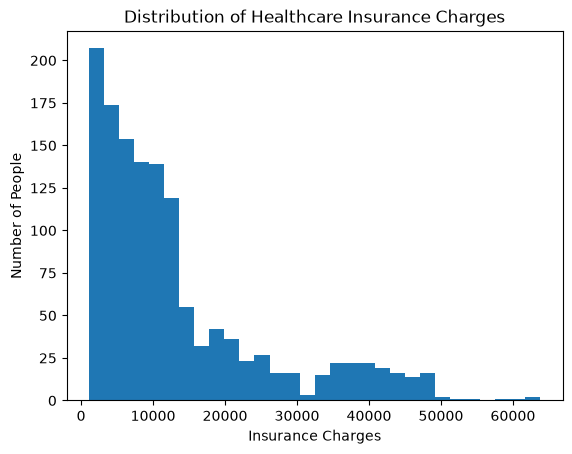

In [33]:

# Create a histogram to examine the distribution and frequency of healthcare insurance charges.
# kind='hist' tells Pandas to create a histogram.
# bins=30 divides the range of insurance charges into 30 intervals (bins) so you can see how frequently charges occur across different ranges.


df["charges"].plot(kind="hist", bins=30)

# Label the x-axis to show the insurance charge values.
plt.xlabel("Insurance Charges")

# Label the y-axis to show the frequency of observations.
plt.ylabel("Number of People")

# Add a descriptive title to the histogram.
plt.title("Distribution of Healthcare Insurance Charges")

# Display the completed histogram.
plt.show()

### Code Explanation

The code uses Pandas and Matplotlib to create and display a histogram showing the distribution of healthcare insurance charges.

- `df["charges"]` selects the insurance charges column from the dataset.
- `.plot(kind="hist")` creates a histogram to display the distribution of insurance charges.
- `bins=30` divides the range of insurance charges into 30 intervals (bins).
- `plt.xlabel()` labels the x-axis as "Insurance Charges".
- `plt.ylabel()` labels the y-axis as "Number of People".
- `plt.title()` adds a descriptive title to the histogram.
- `plt.show()` displays the completed histogram.

The histogram helps identify the distribution of insurance charges, including where values are concentrated and whether the distribution is skewed.

### Interpretation of Insurance Charge Distribution using Histogram:

The histogram shows that most people in the dataset have relatively low insurance charges.

There are fewer people with higher insurance charges, and only a small number of people have very high charges. This creates a long tail on the right side of the histogram, which means the data is right-skewed.

The high charges are important because they can increase the overall average (mean) insurance charge. Therefore, it is useful to look at both the mean and the median when understanding the typical insurance cost.

**Finding: The histogram shows a right-skewed distribution of insurance charges. Most individuals have relatively low charges, while a smaller number have very high charges, creating a long tail on the right. This indicates that insurance charges are not evenly distributed across the dataset.**

### Comparing Average Charges by Smoking Status

I used `groupby()` to separate the data into smokers and non-smokers. I then used `mean()` to calculate the average insurance charge for each group.

This gives us a numerical comparison before creating a **bar chart** to visualise the difference more clearly.

In [34]:

# Find the average insurance charge for smokers and non-smokers.
df.groupby("smoker")["charges"].mean()


smoker
no      8440.660307
yes    32050.231832
Name: charges, dtype: float64

### Initial Finding: Smoking Status and Insurance Charges

The average insurance charge for non-smokers is approximately 8,441, while the average charge for smokers is approximately 32,050.

This shows a substantial difference in average insurance charges between the two groups. The average charge for smokers is approximately 3.8 times higher than for non-smokers.

This is an initial finding rather than evidence that smoking directly causes higher insurance charges. Other variables in the dataset, such as age, BMI, number of children and region, may also influence insurance costs. Further analysis and visualisation will therefore be used to investigate this relationship.

The following bar chart compares the average insurance charges for smokers and non-smokers. The data is grouped by smoking status, and the mean insurance charge is calculated for each group. A bar chart is used to make the difference between the two averages easier to compare visually.

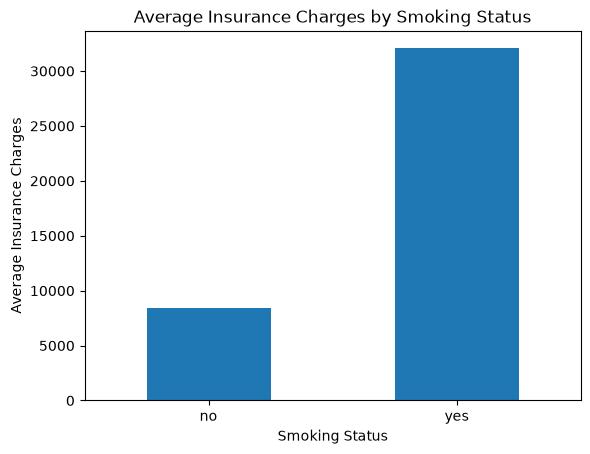

In [35]:

# Calculate the average insurance charges for each smoking-status category and display the results as a bar chart.
# (.plot(kind="bar")turns the two averages into a bar chart)

df.groupby("smoker")["charges"].mean().plot(kind="bar")


# Label the x-axis to identify the smoking-status categories.

plt.xlabel("Smoking Status")

# Label the y-axis to show the average insurance charges.

plt.ylabel("Average Insurance Charges")

# Add a descriptive title to the chart.

plt.title("Average Insurance Charges by Smoking Status")

# Keep the smoking-status labels horizontal for easier reading.

plt.xticks(rotation=0)

# Display the completed bar chart.

plt.show()

### Interpretation of Average Insurance Charges by Smoking Status Using a Bar Chart

The bar chart makes the difference in average insurance charges between smokers and non-smokers easier to see. The bar for smokers is substantially higher than the bar for non-smokers.

Non-smokers have an average insurance charge of approximately 8,441, compared with approximately 32,050 for smokers. This shows that the average charge for smokers is approximately 3.8 times higher than for non-smokers in this dataset.

This finding is relevant to the insurance industry because smoking status is strongly associated with insurance costs in this dataset. However, the chart shows an association rather than proving causation. Other factors, such as age, BMI and number of children, may also influence insurance charges.

### Seaborn Visualisation Methods Used

Seaborn is a Python visualisation library built on Matplotlib. It provides statistical charts that are useful for exploring distributions, comparisons and relationships within a dataset.

The following table summarises the Seaborn visualisation methods used in this project.

| Visualisation | Method Used | Variables Analysed | Purpose | Library Used |
|---|---|---|---|---|
| Scatter Plot | `sns.scatterplot(data=df, x="age", y="charges")` | Age and insurance charges | To investigate how insurance charges vary with age. | Seaborn |
| Box Plot | `sns.boxplot(data=df, x="bmi_category", y="charges")` | BMI categories and insurance charges | To examine differences in insurance charges across BMI categories. | Seaborn |
| Box Plot | `sns.boxplot(data=df, x="children", y="charges")` | Number of children and insurance charges | To compare the distribution of insurance charges across the different numbers of children. | Seaborn |
| Count Plot | `sns.countplot(x="children", data=df)` | Number of children | To show the number of individuals in each children category and identify differences in group sizes. | Seaborn |
| Box Plot | `sns.boxplot(data=df, x="sex", y="charges")` | Sex and insurance charges | To compare the distribution of insurance charges between females and males. | Seaborn |
| Heatmap | `sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")` | Age, BMI, number of children and insurance charges | To visualise the strength and direction of correlations between numerical variables. | Seaborn |

### Relationship Between Age and Insurance Charges

A scatter plot is used to investigate the relationship between age and insurance charges. Seaborn is used to visualise the individual observations and identify any patterns or trends between age and insurance costs.

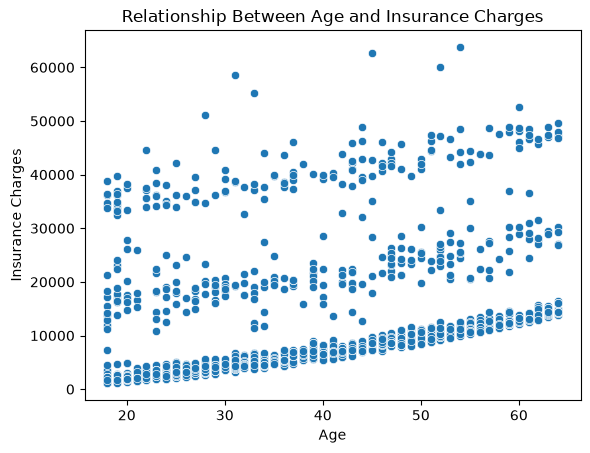

In [36]:


# Create a Seaborn scatter plot to investigate the relationship between age and insurance charges.
sns.scatterplot(data=df, x="age", y="charges")

# Label the x-axis to show the age of the individuals.
plt.xlabel("Age")

# Label the y-axis to show the insurance charges.
plt.ylabel("Insurance Charges")

# Add a descriptive title to the scatter plot.
plt.title("Relationship Between Age and Insurance Charges")

# Display the completed scatter plot.
plt.show()


### Interpretation of Age and Insurance Charges

The scatter plot shows that insurance charges are widely distributed across different ages. Most observations are concentrated at lower charge levels, while some higher insurance charges occur across the age range.

The relationship between age and insurance charges does not appear to be a simple linear pattern. The wide spread of charges at different ages suggests that other factors in the dataset may also be associated with insurance costs.

This visualisation provides an initial view of the relationship between age and insurance charges, which can be explored further using other variables and visualisations.

### Finding

**The scatter plot suggests that age is associated with insurance charges, with higher charges appearing across the age range. However, the wide variation in charges indicates that age alone does not explain differences in insurance costs. Other variables, particularly smoking status and BMI, should also be considered in the analysis.**

### BMI Categories and Insurance Charges

BMI is a numerical variable that can take many different values. To make the comparison easier to interpret, the BMI values are grouped into four categories: Underweight, Normal, Overweight and Obese.

A new column called `bmi_category` will be created from the existing `bmi` column. This categorical variable will then be used to compare insurance charges across the BMI categories using a Seaborn box plot.

### Creating the BMI Categories

The `pd.cut()` function is used to divide continuous numerical BMI values into defined ranges. Each range is then given a meaningful category label.

The BMI categories used are:

- Underweight: BMI below 18.5
- Normal: BMI from 18.5 to below 25
- Overweight: BMI from 25 to below 30
- Obese: BMI 30 and above

This creates a new categorical variable called `bmi_category` while keeping the original `bmi` column unchanged.

In [37]:
# Create a new BMI category column by grouping the existing BMI values into defined ranges.
df["bmi_category"] = pd.cut(
    df["bmi"],  # Use the existing BMI values from the DataFrame.
    bins=[0, 18.5, 25, 30, float("inf")],  # Define the boundaries for the four BMI categories.
    labels=["Underweight", "Normal", "Overweight", "Obese"],  # Assign a category label to each BMI range.
    right=False  # Include the lower boundary and exclude the upper boundary of each range.
)

### Explanation of the Code

- **`df["bmi_category"]`**: Creates a new column called `bmi_category` in the DataFrame to store the BMI categories.

- **`pd.cut()`**: Divides the numerical BMI values into the specified ranges and assigns each value to a category.

- **`df["bmi"]`**: Uses the existing `bmi` column as the source of the values to be categorised.

- **`bins`**: Defines the boundaries of the four BMI categories: 0, 18.5, 25, 30 and infinity.

- **`labels`**: Assigns the category names: Underweight, Normal, Overweight and Obese.

- **`right=False`**: Includes the lower boundary of each range and excludes its upper boundary. For example, a BMI of 25 is classified as Overweight.

- **`float("inf")`**: Represents infinity, allowing the Obese category to include BMI values of 30 and above without a specified upper limit.

### Checking the New BMI Category Column

The new `bmi_category` column is checked alongside the original BMI values to confirm that the BMI values have been assigned to the appropriate categories.

This is a verification step before creating the visualisation.

In [38]:
# Display the original BMI values and the newly created BMI categories to verify the categorisation.
df[["bmi", "bmi_category"]].head(10)

,bmi,bmi_category
0,27.900,Overweight
1,33.770,Obese
2,33.000,Obese
3,22.705,Normal
4,28.880,Overweight
5,25.740,Overweight
6,33.440,Obese
7,27.740,Overweight
8,29.830,Overweight
9,25.840,Overweight


### Distribution of Insurance Charges by BMI Category

A box plot is used to compare the distribution of insurance charges across the four BMI categories.

The box plot allows the median, spread and potential outliers of insurance charges to be compared between the BMI categories. This provides more information than comparing only the average charge for each category.

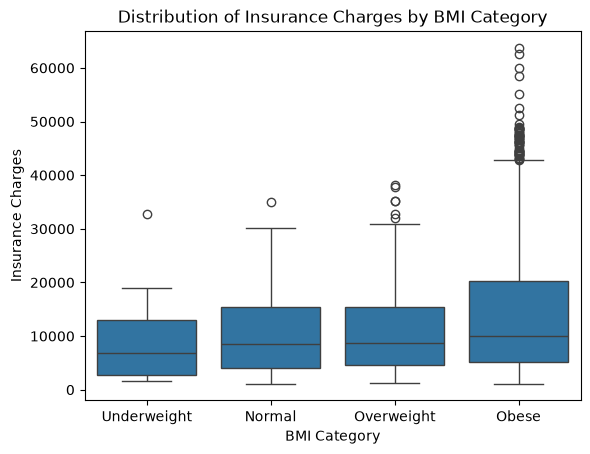

In [39]:
# Create a Seaborn box plot to compare the distribution of insurance charges across BMI categories.
sns.boxplot(data=df, x="bmi_category", y="charges")

# Label the x-axis to identify the BMI categories.
plt.xlabel("BMI Category")

# Label the y-axis to show healthcare insurance charges.
plt.ylabel("Insurance Charges")

# Add a descriptive title to the box plot.
plt.title("Distribution of Insurance Charges by BMI Category")

# Display the completed box plot.
plt.show()

### Interpretation of BMI Categories and Insurance Charges

The box plot shows some differences in insurance charges across the BMI categories. The underweight category generally shows lower charges, while the obese category shows somewhat higher charges.

The normal-weight and overweight categories have relatively similar distributions. Overall, the differences between the BMI categories appear less pronounced than the differences observed between smokers and non-smokers.

This suggests that BMI may be associated with insurance charges, but other factors are also likely to contribute to the variation in costs.

### Number of Children and Insurance Charges

The number of children is investigated to examine whether insurance charges differ between individuals with different numbers of children.

A Seaborn box plot is used because the `children` variable contains a small number of discrete values (0 to 5). This allows the distribution of insurance charges to be compared for each number of children.

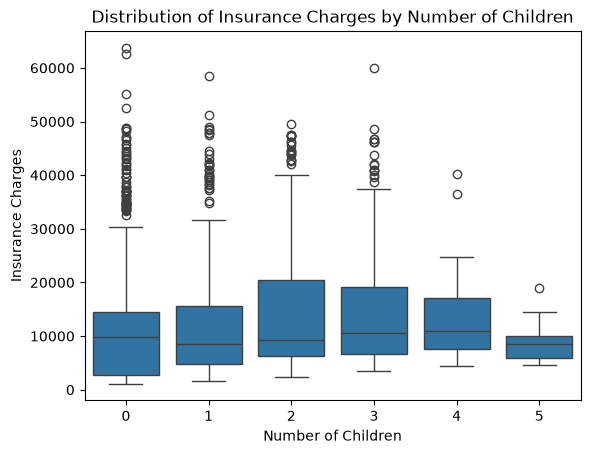

In [40]:
# Create a Seaborn box plot to compare insurance charges for different numbers of children.
sns.boxplot(data=df, x="children", y="charges")

# Label the x-axis to show the number of children.
plt.xlabel("Number of Children")

# Label the y-axis to show healthcare insurance charges.
plt.ylabel("Insurance Charges")

# Add a descriptive title to the box plot.
plt.title("Distribution of Insurance Charges by Number of Children")

# Display the completed box plot.
plt.show()

### Interpretation of Insurance Charges by Number of Children

The box plot shows variation in insurance charges across the different numbers of children. The groups with two and three children show relatively wide distributions, with median charges appearing to be higher than those of some other groups.

The group with no children contains several high-value outliers, including insurance charges above 60,000. The groups with four and five children show narrower distributions and fewer visible outliers. However, these groups may contain fewer observations, which should be considered when comparing their distributions.

Overall, the box plot does not show a clear pattern of insurance charges consistently increasing or decreasing with the number of children. Other factors, such as smoking status, age and BMI, may also contribute to differences in insurance charges.

### Distribution of Individuals by Number of Children

A Seaborn count plot is used to show the number of individuals in each children category.

This visualisation complements the box plot by showing how many observations are available for each group. This is important when interpreting the insurance-charge distributions because groups with very few observations may produce less reliable comparisons.

In [41]:

# Count the number of people in each children category and display the results in numerical order from 0 to 5.

df['children'].value_counts().sort_index()

children
0    573
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64

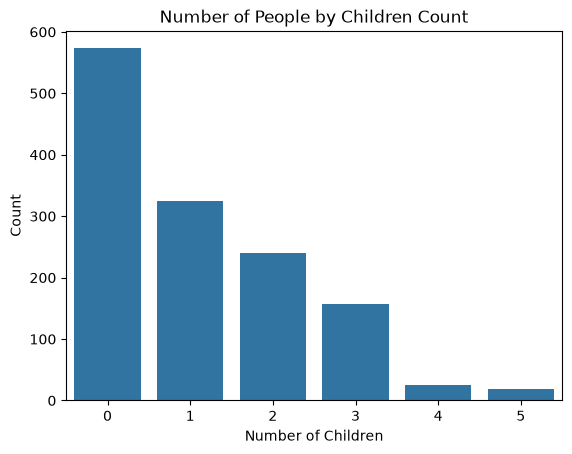

In [42]:
sns.countplot(x="children", data=df)  # Create a Seaborn count plot showing the number of people in each children group.

plt.title("Number of People by Children Count")  # Add a descriptive title to the chart.
plt.xlabel("Number of Children")  # Label the x-axis with the number of children.
plt.ylabel("Count")  # Label the y-axis with the number of people.

plt.show()  # Display the completed count plot.


### Interpretation of Number of People by Children Count

The count plot shows that the dataset contains the largest number of individuals with no children, followed by individuals with one and two children.

The number of individuals decreases as the number of children increases. The groups with four and five children contain very few observations compared with the other groups.

This uneven distribution is important when interpreting the insurance-charge box plot, as conclusions about the smaller groups should be made with caution.

### Why Two Visualisations Are Used

The count plot and box plot provide different information about the `children` variable.

- **Count plot:** shows how many people are in each number-of-children group.
- **Box plot:** shows how insurance charges are distributed within each number-of-children group.

The count plot helps assess the size of each group, while the box plot helps compare insurance charges between the groups. Using both visualisations provides a clearer understanding of the data.

### Sex and Insurance Charges

The sex variable is analysed to investigate whether the distribution of healthcare insurance charges differs between females and males.

A Seaborn box plot is used to compare the distribution, median and spread of insurance charges between the two groups. This helps identify any noticeable differences in insurance charges between females and males.

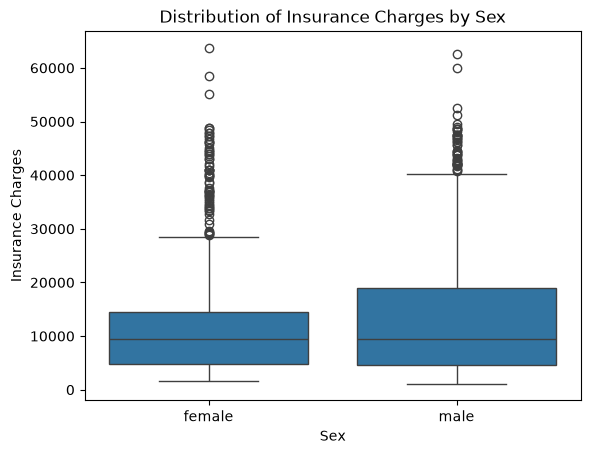

In [43]:
# Create a Seaborn box plot to compare insurance charges between female and male individuals.
sns.boxplot(data=df, x="sex", y="charges")

# Label the x-axis to show the sex categories.
plt.xlabel("Sex")

# Label the y-axis to show healthcare insurance charges.
plt.ylabel("Insurance Charges")

# Add a descriptive title to the chart.
plt.title("Distribution of Insurance Charges by Sex")

# Display the completed box plot.
plt.show()

### Interpretation of Insurance Charges by Sex

The box plot shows some differences in the distribution of insurance charges between females and males. The male group shows a wider spread of charges and extends to higher values than the female group.

However, the two distributions overlap considerably, suggesting that sex alone may not explain the differences in insurance charges. Other factors in the dataset, such as smoking status, age and BMI, may also contribute to variations in insurance costs.

Overall, the differences in insurance charges between females and males appear less pronounced than those observed for smoking status.

### Matplotlib Visualisation Method Used – Region and Insurance Charges

A bar chart is used to compare the average healthcare insurance charges across the four geographic regions.

The chart is created using Pandas plotting, which uses Matplotlib as the underlying visualisation library. This visualisation supports the geographic analysis by highlighting differences in average insurance charges between regions.

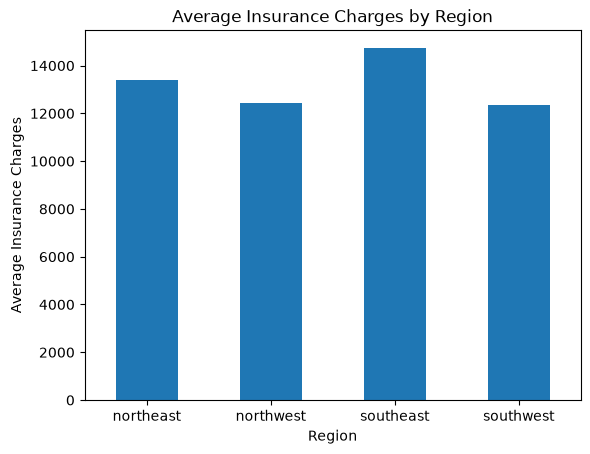

In [44]:
# Calculate the average insurance charges for each region and create a bar chart.
df.groupby("region")["charges"].mean().plot(kind="bar")

# Label the x-axis with the geographic regions.
plt.xlabel("Region")

# Label the y-axis with the average insurance charges.
plt.ylabel("Average Insurance Charges")

# Add a descriptive title to the chart.
plt.title("Average Insurance Charges by Region")

# Keep the region names horizontal for easier reading.
plt.xticks(rotation=0)

# Display the completed bar chart.
plt.show()

### Checking Average Insurance Charges by Region

The average insurance charges for each geographic region are calculated and displayed numerically to support the interpretation of the bar chart. These values provide a more precise comparison of average insurance charges across the four regions.

In [45]:
# Calculate and display the average insurance charges for each region.
df.groupby("region")["charges"].mean().round(2)

region
northeast    13406.38
northwest    12450.84
southeast    14735.41
southwest    12346.94
Name: charges, dtype: float64

### Explanation of the Code

- **`df.groupby("region")`**: Groups the records by the four geographic regions.

- **`["charges"]`**: Selects the insurance charges column.

- **`.mean()`**: Calculates the average insurance charges for each region.

- **`.plot(kind="bar")`**: Creates a bar chart to display the average charges for each region.

- **`plt.xlabel()`**: Labels the x-axis with the geographic regions.

- **`plt.ylabel()`**: Labels the y-axis with the average insurance charges.

- **`plt.title()`**: Adds a descriptive title to the chart.

- **`plt.xticks(rotation=0)`**: Keeps the region names horizontal for easier reading.

- **`plt.show()`**: Displays the completed chart.

### Interpretation of Average Insurance Charges by Region

The bar chart shows differences in average insurance charges across the four geographic regions.

The southeast region has the highest average insurance charges, at approximately 14,735.41. The northeast region follows, with average charges of approximately 13,406.38. The northwest and southwest regions have lower average charges of approximately 12,450.84 and 12,346.94, respectively.

Overall, the southeast region has the highest average insurance charges, while the southwest region has the lowest. This suggests that geographic region may be associated with differences in insurance charges. However, these differences do not establish that region causes higher or lower charges, as other factors may also contribute to insurance costs.

### Overall Comparison of Insurance Charges

The previous visualisations examined how insurance charges vary across individual variables, including age, BMI, number of children, smoking status, sex and geographic region.

This section brings these findings together to compare the differences observed across these variables. It provides an overview of the factors associated with variations in insurance charges and leads into the subsequent correlation analysis.

### Transition from Descriptive Analysis to Correlation Analysis

The descriptive analysis and visualisations have explored how insurance charges vary across age, BMI, smoking status, number of children, sex and geographic region.

Correlation analysis is used next to examine the strength and direction of linear relationships between numerical variables and insurance charges. This provides additional insight into the relationships between these variables and complements the findings from the earlier visualisations.

The correlation results will be considered alongside the descriptive analysis when drawing conclusions about the factors associated with insurance charges.

### Correlation Analysis

Correlation analysis examines the strength and direction of linear relationships between numerical variables in the dataset.

This analysis focuses on age, BMI, number of children and insurance charges. The Pearson correlation coefficient ranges from -1 to +1. A value closer to +1 indicates a stronger positive linear relationship, while a value closer to -1 indicates a stronger negative linear relationship. A value close to 0 indicates little or no linear relationship.

Correlation does not prove that one variable causes another. It measures the strength and direction of a relationship, but other factors may also influence insurance charges.

In [46]:
# Select the numerical variables and calculate their correlation coefficients.
correlation_matrix = df[["age", "bmi", "children", "charges"]].corr()

# Display the correlation matrix.
correlation_matrix

,age,bmi,children,charges
age,1.000000,0.109344,0.041536,0.298308
bmi,0.109344,1.000000,0.012755,0.198401
children,0.041536,0.012755,1.000000,0.067389
charges,0.298308,0.198401,0.067389,1.000000


### Explanation of the Code

- **`df[["age", "bmi", "children", "charges"]]`**: Selects the numerical variables used in the correlation analysis.

- **`.corr()`**: Calculates the Pearson correlation coefficients between each pair of selected numerical variables.

- **`correlation_matrix`**: Stores the calculated correlation coefficients in a DataFrame.

- **The final line of code**: Displays the correlation matrix so that the relationships between the numerical variables can be examined.

### Interpretation of Correlation Analysis

The correlation analysis shows that age has the strongest positive linear relationship with insurance charges among the numerical variables examined, with a correlation coefficient of approximately 0.30.

BMI has a weaker positive linear relationship with insurance charges, with a correlation coefficient of approximately 0.20.

The number of children has a very weak positive linear relationship with insurance charges, with a correlation coefficient of approximately 0.07.

Overall, age has the strongest linear relationship with insurance charges among these numerical variables. However, all three correlations are relatively weak, indicating that these variables alone do not fully explain the variation in insurance charges.

The correlations between age, BMI and number of children are also weak, suggesting little linear relationship between these variables. These results describe associations rather than proving that any variable causes changes in insurance charges.

### Correlation Heatmap Using Seaborn

Seaborn is used to create a correlation heatmap that visually represents the relationships between the numerical variables in the dataset.

The heatmap uses colour to show the strength and direction of the correlations between age, BMI, number of children and insurance charges. This visualisation complements the numerical correlation matrix by making patterns in the relationships easier to identify.

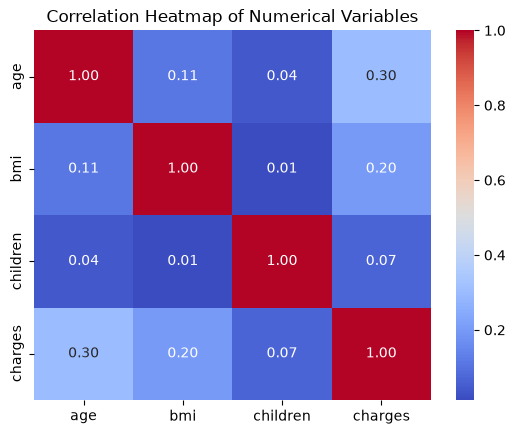

In [47]:
# Create a Seaborn heatmap to visually display the correlation matrix.
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")

# Add a title to the heatmap.
plt.title("Correlation Heatmap of Numerical Variables")

# Display the heatmap.
plt.show()

### Explanation of the Code

- **`sns.heatmap()`**: Displays the correlation matrix as a colour-coded heatmap.
- **`annot=True`**: Displays the correlation values inside the heatmap cells.
- **`cmap="coolwarm"`**: Applies a colour scheme to help distinguish positive and negative correlations.
- **`fmt=".2f"`**: Formats the displayed correlation values to two decimal places.
- **`plt.title()`**: Adds a descriptive title to the heatmap.
- **`plt.show()`**: Displays the completed chart.

The heatmap makes it easier to identify the strength and direction of relationships between the numerical variables.

### Interpretation of the Correlation Heatmap

The correlation heatmap shows the strength and direction of linear relationships between the numerical variables.

Age has the strongest positive correlation with insurance charges among the numerical variables examined, at approximately 0.30. BMI has a weaker positive correlation of approximately 0.20, while the number of children has a very weak positive correlation of approximately 0.07.

Overall, the heatmap confirms that age has the strongest linear relationship with insurance charges among these numerical variables. However, these relationships are relatively weak and do not fully explain the variation in insurance charges. Other factors, particularly categorical variables such as smoking status, should also be considered when interpreting the overall findings.

Correlation indicates an association between variables but does not prove that one variable causes changes in another.

### Plotly Visualisation Method Used

Plotly is used to create an interactive scatter plot showing the relationship between age and insurance charges, with smoking status represented by colour.

The interactive chart allows users to explore individual observations and distinguish between smokers and non-smokers across different ages.

This visualisation complements the earlier Seaborn scatter plot by adding interactivity and making it easier to explore how insurance charges vary with age and smoking status.

In [48]:
# Verify the Python interpreter being used by the notebook.
import sys
print(sys.executable)


import nbformat
print(nbformat.__version__)

c:\Users\kavit\OneDrive\Desktop\Healthcare_Insurance_Assessment2\.venv\Scripts\python.exe
5.11.1


### Development Challenge: Plotly Chart Not Displaying

When I ran the Plotly code in this new project environment, the chart did not display and I got this error: "Mime type rendering requires nbformat>=4.2.0 but it is not installed".

**Investigation:**
- I checked that `nbformat` was installed using the terminal and `%pip install nbformat`, which both reported that it was already installed.
- I restarted the kernel, but the error remained.
- I tested `import nbformat` directly in a notebook cell, which revealed the real problem: `ModuleNotFoundError: No module named 'rpds.rpds'`.

**Cause:** `rpds-py`, a package that `nbformat` depends on, was damaged or incomplete in this virtual environment. This stopped `nbformat` from importing, so Plotly reported that it was not installed.

**Solution:** I reinstalled `rpds-py` with `pip install --force-reinstall --no-cache-dir rpds-py`, restarted the kernel and confirmed that `nbformat` imported correctly. The Plotly chart then displayed.

The two cells above confirm the Python environment and the `nbformat` version used for this project.


In [49]:
# Create an interactive scatter plot showing age and insurance charges,
# with smoking status represented by colour.
fig = px.scatter(
    df,
    x="age",
    y="charges",
    color="smoker",
    title="Age and Insurance Charges by Smoking Status",
    labels={
        "age": "Age",
        "charges": "Insurance Charges",
        "smoker": "Smoking Status"
    }
)

# Save the interactive Plotly chart as an HTML file.
fig.write_html("age_insurance_smoking_plot.html")

# Display the interactive Plotly chart in the notebook.
fig.show()

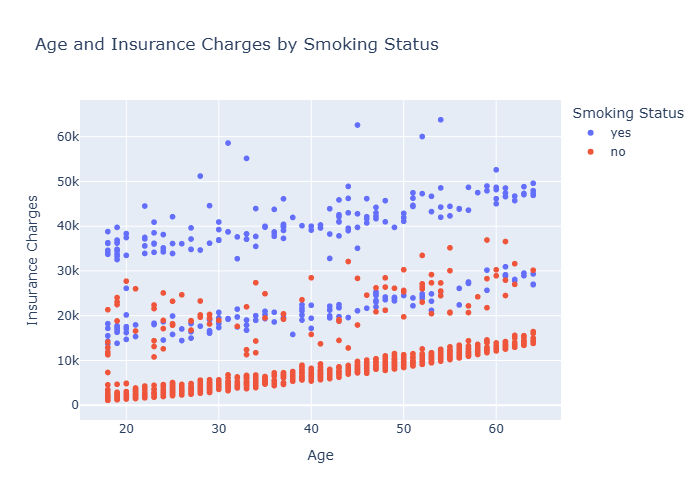

In [50]:
fig.show("png")

Note: The interactive Plotly chart above does not display in GitHub's notebook preview, so a static image version of the same chart is included below. The interactive version is also saved as age_insurance_smoking_plot.html in the notebooks folder.

### Interpretation of the Plotly Visualisation

The chart shows a clear difference between smokers and non-smokers. Colouring the points by smoking status makes it easy to see that the two groups sit at very different charge levels.

Non-smokers are mostly at the lower end of insurance charges, and their charges rise gradually as age increases. Smokers' charges are mostly much higher and more spread out, with the points sitting above most non-smokers across the age range.

The chart also shows that some younger smokers have higher insurance charges than older non-smokers. Age still shows a gradual upward pattern within each group, but smoking status appears to have a stronger association with insurance charges than age alone. This matches the earlier comparison of averages, where smokers averaged approximately 32,050 and non-smokers approximately 8,441.

**Smoking status appears to have a stronger association with insurance charges than age alone in this visualisation.** This is an association within the data, not proof that smoking directly causes higher charges.


## Hypothesis

The analysis hypothesises that lifestyle and personal factors, particularly smoking status, age and BMI, are associated with differences in healthcare insurance charges.

It is expected that smokers will have higher insurance charges than non-smokers, while older age and higher BMI will also be associated with higher charges.

The exploratory analysis was used to assess whether the observed results support this hypothesis.


## Overall Comparison of Insurance Charges by Key Factors

The descriptive analysis has examined the relationship between insurance charges and individual variables.

The next stage compares average insurance charges across the categorical variables to identify which factors show the largest differences in insurance costs.

This comparison helps identify which categorical variables are most strongly associated with insurance charges in this dataset.

In [51]:
# Calculate the average insurance charges for smokers and non-smokers.
average_charges_smoker = df.groupby('smoker')['charges'].mean()

# Display the average insurance charges for each smoking-status group.
average_charges_smoker

smoker
no      8440.660307
yes    32050.231832
Name: charges, dtype: float64

#### Code Explanation

The `groupby()` function groups the data by smoking status, and `.mean()` calculates the average insurance charges for smokers and non-smokers. This makes it possible to compare the average charges between the two groups.

**Finding:** Smokers have substantially higher average insurance charges than non-smokers. The average charge for smokers is approximately 32,050, compared with approximately 8,441 for non-smokers. This is the largest difference observed among the factors examined and suggests that smoking status is strongly associated with insurance charges in this dataset.

### Average Insurance Charges by Sex, Region and Number of Children

The average insurance charges are calculated for each sex, geographical region and number of children to compare differences in insurance costs across these groups.

In [52]:
# Calculate the average insurance charges for each sex.
average_charges_sex = df.groupby('sex')['charges'].mean()

# Calculate the average insurance charges for each region.
average_charges_region = df.groupby('region')['charges'].mean()

# Calculate the average insurance charges for each number of children.
average_charges_children = df.groupby('children')['charges'].mean()

# Display the average charges for each categorical variable.
print("Average insurance charges by sex:")
print(average_charges_sex)

print("\nAverage insurance charges by region:")
print(average_charges_region)

print("\nAverage insurance charges by number of children:")
print(average_charges_children)

Average insurance charges by sex:
sex
female    12569.578844
male      13974.998864
Name: charges, dtype: float64

Average insurance charges by region:
region
northeast    13406.384516
northwest    12450.840844
southeast    14735.411438
southwest    12346.937377
Name: charges, dtype: float64

Average insurance charges by number of children:
children
0    12384.695344
1    12731.171832
2    15073.563734
3    15355.318367
4    13850.656311
5     8786.035247
Name: charges, dtype: float64


#### Code Explanation

The `groupby()` function groups the data by sex, region and number of children, while `.mean()` calculates the average insurance charges for each group. This allows the average charges across these groups to be compared.

**Finding:** Average insurance charges are higher for males than females, although the difference is much smaller than the difference between smokers and non-smokers. The Southeast has the highest average charges among the regions, while the Southwest has the lowest. Average charges also vary across groups with different numbers of children, but they do not show a consistent increasing pattern. Overall, these comparisons indicate that sex, region and number of children show smaller or less consistent differences in charges than smoking status.

## Comparison of Numerical Variables

The correlation values are visualised to compare the strength of the linear relationship between age, BMI, number of children and insurance charges.

This chart provides a direct comparison of the numerical variables and complements the earlier scatter plots and correlation heatmap.

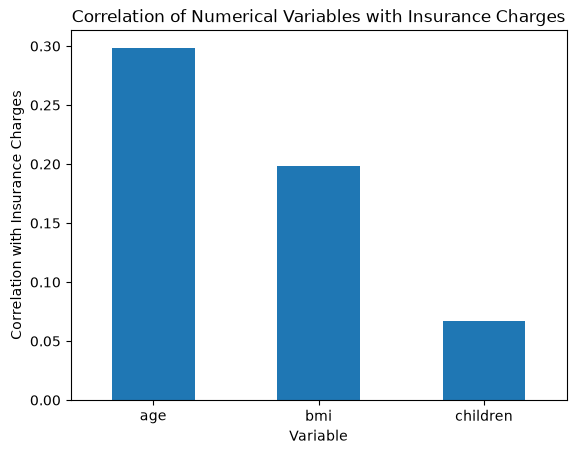

In [53]:
# Select the correlations between the numerical variables and insurance charges.
correlation_with_charges = df[['age', 'bmi', 'children', 'charges']].corr()['charges'].drop('charges')

# Create a bar chart to compare the numerical correlations with insurance charges.
correlation_with_charges.plot(kind='bar')

# Add labels and a title to the chart.
plt.title("Correlation of Numerical Variables with Insurance Charges")
plt.xlabel("Variable")
plt.ylabel("Correlation with Insurance Charges")
plt.xticks(rotation=0)
plt.show()

### Interpretation of the Correlation Comparison

Age shows the strongest positive correlation with insurance charges among the numerical variables, at approximately 0.30.

BMI shows a weaker positive correlation of approximately 0.20, while the number of children has a very weak positive correlation of approximately 0.07.

This indicates that age has the strongest linear relationship with insurance charges among these numerical variables, although the correlations are not strong enough to explain insurance charges on their own.

The earlier analysis of smoking status provides additional evidence that smoking status shows a much larger difference in average insurance charges than the numerical variables considered here.

## Hypothesis Result

The analysis provides evidence that supports the hypothesis that personal and lifestyle factors are associated with differences in healthcare insurance charges.

Smoking status shows the largest difference, with smokers having substantially higher average insurance charges than non-smokers.

Age and BMI also show positive relationships with insurance charges, although their correlations are weaker than the difference observed for smoking status.

Sex and region show smaller differences in average charges, while the number of children does not show a clear or consistent relationship with insurance charges.

Therefore, the findings support the hypothesis overall, while also showing that different factors have different strengths of association with insurance charges. These findings describe relationships within the dataset and do not establish causation.


## Final Findings: Factors Associated with Insurance Charges

The exploratory data analysis examined age, BMI, smoking status, sex, region and number of children in relation to healthcare insurance charges.

The results indicate that **smoking status shows the strongest difference in insurance charges**. The average charge for smokers is approximately 32,050, compared with approximately 8,441 for non-smokers.

**Age** shows a moderate positive correlation with insurance charges (approximately 0.30), indicating that charges tend to increase as age increases.

**BMI** shows a weaker positive correlation with insurance charges (approximately 0.20), suggesting that higher BMI is associated with somewhat higher charges, although the relationship is weaker than age.

**Region** shows some differences in average insurance charges. The Southeast has the highest average charge, while the Southwest has the lowest. However, these differences are considerably smaller than the difference observed between smokers and non-smokers.

**Sex** shows a relatively small difference in average charges, with males having higher average charges than females.

**Number of children** does not show a consistent pattern of increasing insurance charges as the number of children increases. Therefore, the number of children appears to have a weaker and less consistent association with charges in this dataset.

Overall, the analysis suggests that **smoking status is the most prominent factor associated with differences in healthcare insurance charges**, followed by age and BMI. Region and sex show smaller differences, while the number of children does not show a clear consistent relationship.

These findings are based on exploratory analysis and describe associations within this dataset; they do not establish that any individual factor directly causes higher insurance charges.

# Final Conclusion

The analysis shows that several personal and lifestyle factors are associated with differences in healthcare insurance charges.

Smoking status has the strongest observed difference, with smokers having substantially higher average insurance charges than non-smokers. Age also shows a positive relationship with charges, while BMI has a weaker positive relationship.

Differences in insurance charges are also observed across sex and region, although these differences are smaller. The number of children does not show a clear or consistent relationship with insurance charges in this dataset.

Overall, the exploratory analysis indicates that smoking status is the most prominent factor associated with insurance charges, followed by age and BMI. These findings demonstrate how healthcare insurance data can be analysed to identify patterns in costs and support further investigation.

The findings represent associations within this dataset and should not be interpreted as proof that any individual factor directly causes higher insurance charges. Further analysis and predictive modelling could be used to investigate these relationships in greater depth.


# Section 5: Machine Learning — Predicting Healthcare Insurance Charges

## Introduction

Machine Learning is used in this project to predict healthcare insurance charges based on personal and lifestyle factors. A Linear Regression model will be developed and evaluated to assess how accurately it can predict insurance charges using the available dataset.

### Model Selection



Linear Regression was selected as the primary supervised machine learning model because the target variable, `charges`, contains continuous numerical values. The aim is to predict healthcare insurance charges using features such as age, BMI, number of children, sex, smoking status, region, and BMI category.

Linear Regression estimates the relationship between these input features and insurance charges. Its relatively simple structure makes it easier to interpret and explain, providing a suitable starting point for supervised learning in this project.

The model's predictive performance will be evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the R² score. Although Linear Regression is suitable for predicting numerical outcomes, it may not capture every complex relationship in the dataset. Random Forest Regression will therefore be used as a comparison model to investigate whether an alternative approach improves predictive performance.

### Preparing the Data

The cleaned dataset will be used to separate the input features from the target variable. The input features will be used to predict `charges`, which is the target variable.

In [54]:
# Separate the input features from the target variable.
X = df.drop(columns=['charges'])
y = df['charges']

# Display the shapes of the features and target.
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1337, 7)
Target shape: (1337,)


**Finding:** The dataset contains 1,337 records. Seven input features are available to predict the target variable, `charges`.

### Encoding Categorical Variables

Categorical variables such as sex, smoker, and region must be converted into numerical values before training the Linear Regression model. One-hot encoding creates numerical columns for these categories.

In [55]:
# Convert categorical variables into numerical columns.
X = pd.get_dummies(
    X,
    columns=['sex', 'smoker', 'region', 'bmi_category'],
    drop_first=True,
    dtype=int
)

# Display the encoded features.
print("Encoded features shape:", X.shape)
print("Feature columns:", X.columns.tolist())

Encoded features shape: (1337, 11)
Feature columns: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese']


**Finding:** One-hot encoding converted the categorical variables into numerical columns containing 0s and 1s. The resulting dataset contains 1,337 records and 11 numerical input features for model training.

### Splitting the Data into Training and Testing Sets

The dataset is split into training and testing sets. The training set is used to train the model, while the testing set evaluates its performance on unseen data. An 80:20 split is used.

In [56]:
# Split the data into training and testing sets.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Display the shapes of the training and testing sets.
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (1069, 11)
Testing features: (268, 11)
Training target: (1069,)
Testing target: (268,)


**Finding:** The dataset was split into 1,069 training records (80%) and 268 testing records (20%). The testing data will be used to evaluate the model on unseen records.

### Training the Linear Regression Model

The Linear Regression model is trained using the training dataset to learn the relationship between the input features and healthcare insurance charges.

In [57]:
# Train the Linear Regression model.
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


**Finding:** The Linear Regression model trained successfully using the encoded training features. Its predictive performance will be assessed using the separate testing dataset.

### Evaluating the Model

The trained Linear Regression model will be evaluated using the testing dataset. Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the R² score will be used to assess how accurately the model predicts healthcare insurance charges.

In [58]:
# Evaluate the Linear Regression model using the testing data.
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Generate predictions for the testing data.
y_pred = model.predict(X_test)

# Calculate the evaluation metrics.
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Display the evaluation results.
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R² Score:", round(r2, 4))

Mean Absolute Error (MAE): 4334.48
Root Mean Squared Error (RMSE): 6023.86
R² Score: 0.8025


**Finding:** The Linear Regression model achieved an R² score of 0.8025, indicating that it explains approximately 80.25% of the variation in healthcare insurance charges in the testing dataset. The Mean Absolute Error (MAE) was 4,334.48, meaning the model's predictions differed from the actual charges by an average of approximately 4,334.48 monetary units. The Root Mean Squared Error (RMSE) was 6,023.86, reflecting the size of prediction errors while giving greater weight to larger errors.

### Comparing Predicted and Actual Charges

A comparison of predicted and actual insurance charges helps assess how closely the Linear Regression model's predictions match the observed values.

In [59]:
# Compare actual and predicted insurance charges.
comparison = pd.DataFrame({
    'Actual Charges': y_test,
    'Predicted Charges': y_pred
})

# Display the first 10 comparisons.
comparison.head(10).round(2)

,Actual Charges,Predicted Charges
900,8688.86,8268.50
1064,5708.87,5165.76
1256,11436.74,14557.20
298,38746.36,32476.10
237,4463.21,8922.53
481,9304.70,13298.54
240,38511.63,30663.76
277,2150.47,1047.53
415,7345.73,11224.68
707,10264.44,10007.22


**Finding:** The comparison table displays the actual insurance charges alongside the values predicted by the Linear Regression model for the testing dataset. Comparing these values helps assess how closely the model's predictions match the observed insurance charges.

### Visualising Actual vs Predicted Charges

A scatter plot is used to compare actual insurance charges with the charges predicted by the Linear Regression model. Predictions closer to the diagonal reference line indicate better agreement between actual and predicted values.

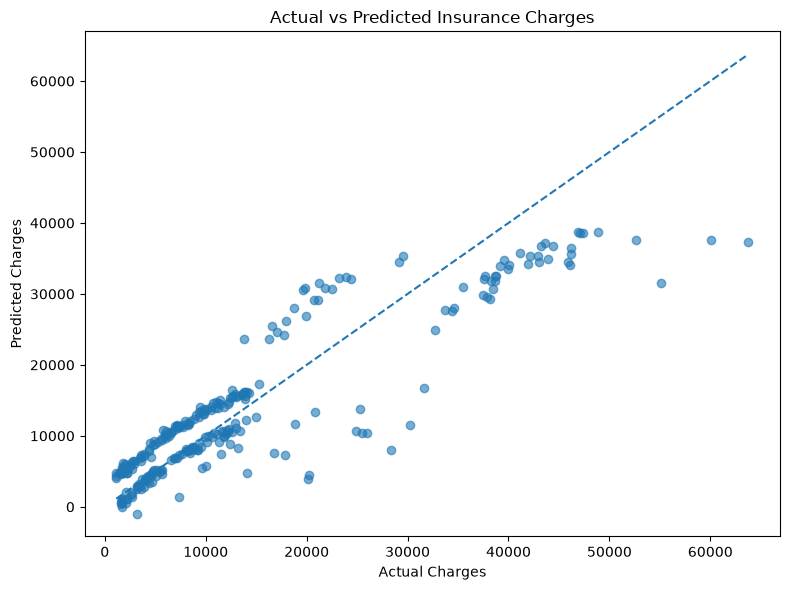

In [60]:
# Visualise actual versus predicted insurance charges.
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

# Add a reference line representing perfect predictions.
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.title('Actual vs Predicted Insurance Charges')
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.tight_layout()
plt.show()

**Finding:** The scatter plot shows a general upward trend, indicating that predicted insurance charges tend to increase as actual charges increase. However, the points are spread around the diagonal reference line, with some predictions differing considerably from the actual values. Points above the line indicate overprediction, while points below the line indicate underprediction. The model achieved an R² score of 0.8025, explaining approximately 80.25% of the variation in healthcare insurance charges in the testing dataset. The Mean Absolute Error (MAE) was 4,334.48, meaning that predictions differed from actual charges by an average of approximately 4,334.48 monetary units. The Root Mean Squared Error (RMSE) was 6,023.86, reflecting the size of prediction errors while giving greater weight to larger errors. Overall, the results indicate that the model captures important relationships in the data, but some predictions remain considerably different from the actual charges.

### Comparing Linear Regression and Random Forest Regression

Random Forest Regression is used as a second model to compare its predictive performance with Linear Regression. Both models will use the same training and testing datasets and will be evaluated using R², Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE). This comparison will help determine which model predicts healthcare insurance charges more accurately on the testing dataset.

### Model Selection: Random Forest Regression

Random Forest Regression was selected as a comparison model because it can predict continuous numerical values, making it suitable for the insurance `charges` target variable. Unlike Linear Regression, which estimates a linear relationship between the input features and the target, Random Forest combines predictions from multiple decision trees to capture more complex relationships in the data.

This comparison helps assess whether a model capable of capturing non-linear relationships can improve predictions of healthcare insurance charges. Both models will be evaluated using the same training and testing datasets and the same three evaluation metrics: MAE, RMSE, and R².

### Training and Evaluating the Random Forest Model

The Random Forest Regression model will be trained using the existing training dataset and then used to predict insurance charges for the testing dataset. Its predictive performance will be evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the R² score. These results will help assess how well the model predicts healthcare insurance charges on unseen data.

In [61]:
# Train and evaluate the Random Forest Regression model.
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Train the model using the existing training dataset.
rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)

# Predict insurance charges using the testing dataset.
rf_pred = rf_model.predict(X_test)

# Calculate the evaluation metrics.
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

# Display the evaluation results.
print("Random Forest Regression model trained successfully.")
print("Mean Absolute Error (MAE):", round(rf_mae, 2))
print("Root Mean Squared Error (RMSE):", round(rf_rmse, 2))
print("R² Score:", round(rf_r2, 4))

Random Forest Regression model trained successfully.
Mean Absolute Error (MAE): 2639.83
Root Mean Squared Error (RMSE): 4673.26
R² Score: 0.8812


### Evaluating the Random Forest Model

Random Forest Regression achieved an R² score of 0.8812, indicating that it explains approximately 88.12% of the variation in healthcare insurance charges in the testing dataset. Its Mean Absolute Error (MAE) was 2,639.83, representing the average absolute difference between predicted and actual charges. Its Root Mean Squared Error (RMSE) was 4,673.26, giving greater weight to larger prediction errors.

These metrics provide an assessment of the model's predictive performance on the testing dataset. The results will now be compared with Linear Regression to determine how the two approaches performed on the same data.

### Comparing Model Performance

The evaluation metrics for Linear Regression and Random Forest Regression are compared below. R² measures how much variation in insurance charges the model explains, while MAE and RMSE measure prediction errors.

In [62]:
# Compare the evaluation metrics of both regression models.
model_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest Regression'],
    'MAE': [mae, rf_mae],
    'RMSE': [rmse, rf_rmse],
    'R² Score': [r2, rf_r2]
})

# Display the comparison results.
model_comparison.round(4)

,Model,MAE,RMSE,R² Score
0,Linear Regression,4334.4814,6023.8562,0.8025
1,Random Forest Regression,2639.8303,4673.2625,0.8812


**Finding:** Random Forest Regression performed better than Linear Regression across all three evaluation metrics, achieving a higher R² score and lower prediction errors on the testing dataset. This suggests that Random Forest captured patterns in the data more effectively for these test records. However, both models still produced prediction errors, and further testing would be needed to assess how well they generalise to other data.

### Machine Learning Conclusion

The project used Linear Regression as the primary model to predict healthcare insurance charges and Random Forest Regression as a second model for comparison. Both models were evaluated using the same testing dataset and three metrics: R², Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE).

Random Forest Regression performed better, achieving an R² score of 0.8812, an MAE of 2,639.83, and an RMSE of 4,673.26. Linear Regression achieved an R² score of 0.8025, an MAE of 4,334.48, and an RMSE of 6,023.86. The results suggest that Random Forest predicted insurance charges more accurately on this test dataset. Nevertheless, neither model eliminates prediction errors, and further testing would be needed to assess how well the models generalise to other data.

# Section 6: Healthcare Insurance Applications and AI Opportunities

### Applications of Analytics in Healthcare Insurance

Healthcare insurance analytics can help identify patterns in insurance costs, explore differences between customer groups and support data-informed decision-making.

In this project, the exploratory analysis identified smoking status as the most prominent factor associated with higher insurance charges. Age and BMI also showed positive relationships with charges. These findings help explain cost patterns within the dataset and highlight areas for further investigation.

In practice, analytics can help healthcare insurers monitor claims and costs, identify unusual patterns, understand customer groups and improve forecasting and planning.

### Challenges and AI Opportunities

A key challenge for healthcare insurers is understanding and predicting the factors associated with higher insurance costs across different customer groups.

AI and predictive analytics offer opportunities to estimate insurance charges using variables such as age, BMI, smoking status, sex, region and number of children. In this project, Linear Regression was used as the primary predictive model, while Random Forest Regression was evaluated for comparison.

The results suggest that predictive models can help estimate insurance charges, but their performance must be evaluated carefully. Models may produce inaccurate predictions or reflect biases in the data. Personal and health-related information must also be handled responsibly, with appropriate attention to privacy, fairness and human oversight.

This project provides a foundation for further investigation into how predictive analytics could support insurance cost forecasting and decision-making. However, the models' performance on this dataset does not establish that they would be suitable for real-world insurance decisions without further validation.

# Section 7: Project Conclusion and Future Improvements

This project explored healthcare insurance charges using data investigation, data cleaning, statistical analysis, visualisation and machine learning. The analysis identified relationships between insurance charges and several customer characteristics, particularly smoking status, age and BMI.

Linear Regression was used as the primary model to predict insurance charges, while Random Forest Regression was evaluated as a comparison. Random Forest achieved better results across the three evaluation metrics on the testing dataset, with a higher R² score and lower prediction errors. However, these results relate to the available dataset and do not guarantee the same performance on other data.

The project demonstrates how data analytics and machine learning can help identify patterns and estimate healthcare insurance costs. It also highlights the importance of data quality, model evaluation and responsible use of personal information.

Future improvements could include developing an interactive Tableau dashboard, investigating additional relevant data, testing model performance on new datasets and exploring methods to improve prediction accuracy. Any practical application would also require further validation and consideration of fairness, privacy and potential bias.